# Deep Learning Final Project Team 2

## Description

## Data

### Import Data

In [11]:
from pathlib import Path

data_dir = Path("data/training")
# print("Working directory:", Path.cwd())
print("Files:", [p.name for p in data_dir.iterdir()])

Files: ['ENCFF262URW.bigWig', 'ENCFF357GNC.bigWig', 'ENCFF667MDI.bigWig', 'ENCFF770EAV.bigWig', 'hg38.fa.gz']


### Features

The features for this dataset (what we're learning from) is the hg38.fa.gz file. This is the standard reference human genome, including about 3.2 billion letters, split into one long sequence per chromosome. Taking a look at the file: 

In [13]:
import gzip
import pandas as pd

TARGET_CHROMS = [f"chr{i}" for i in range(1, 23)]  # chr1-chr22
EXAMPLE_CHROM = "chr1"
EXAMPLE_LEN = 50

records = {}
current = None
name = None
chr1_example = ""

with gzip.open(f"{data_dir}/hg38.fa.gz", "rt") as genome:
    for line in genome:
        if line.startswith(">"):
            name = line[1:].split()[0]
            current = {"sequence": name, "length": 0, "A": 0, "C": 0, "G": 0, "T": 0, "N": 0}
            records[name] = current
        else:
            bases = line.strip().upper()
            current["length"] += len(bases)
            for base in "ACGTN":
                current[base] += bases.count(base)
            if name == EXAMPLE_CHROM and len(chr1_example) < EXAMPLE_LEN:
                chr1_example += bases.replace("N", "")[: EXAMPLE_LEN - len(chr1_example)]

all_sequences = pd.DataFrame(records.values())
all_sequences["other"] = all_sequences["length"] - all_sequences[["A", "C", "G", "T", "N"]].sum(axis=1)

total_sequences = len(all_sequences)
total_bases = int(all_sequences["length"].sum())

chrom_table = (
    all_sequences.set_index("sequence")
    .loc[TARGET_CHROMS]
    .reset_index()
    .rename(columns={"sequence": "chromosome", "other": "other symbols"})
)
chrom_table = chrom_table[["chromosome", "length", "A", "C", "G", "T", "N", "other symbols"]]

used_sequences = len(chrom_table)
used_bases = int(chrom_table["length"].sum())

There are 455 total sequences, 3,209,286,105 total bases, and they are in the form of a list of letters:

In [14]:
print(f"Total sequences: {total_sequences:,}")
print(f"Total bases:     {total_bases:,}")
print(f"\nExample (first {len(chr1_example)} bases of chr1, N skipped):\n{chr1_example}")

Total sequences: 455
Total bases:     3,209,286,105

Example (first 50 bases of chr1, N skipped):
TAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTAACCCTA


Grover et al. only focuses on chromosomes 1-22 (others are sex chromosomes, mitochondrial, and other fragments that are left out for this study). Let's take a deeper look at the chromosome sequences we will actually be using: 

In [15]:
print(f"Sequences used: {used_sequences:,}")
print(f"Bases used:     {used_bases:,}")

display(
    chrom_table.style
    .format({c: "{:,}" for c in chrom_table.columns[1:]})
    .hide(axis="index")
)

Sequences used: 22
Bases used:     2,875,001,522


chromosome,length,A,C,G,T,N,other symbols
chr1,"248,956,422","67,070,277","48,055,043","48,111,528","67,244,164","18,475,410",0
chr2,"242,193,529","71,791,213","48,318,180","48,450,903","71,987,932","1,645,301",0
chr3,"198,295,559","59,689,091","39,233,483","39,344,259","59,833,302","195,424",0
chr4,"190,214,555","58,561,236","36,236,976","36,331,025","58,623,430","461,888",0
chr5,"181,538,259","54,699,094","35,731,600","35,879,674","54,955,010","272,881",0
chr6,"170,805,979","51,345,477","33,646,690","33,713,330","51,373,025","727,457",0
chr7,"159,345,973","47,058,248","32,317,984","32,378,859","47,215,040","375,842",0
chr8,"145,138,636","43,333,530","29,030,173","29,103,787","43,300,646","370,500",0
chr9,"138,394,717","35,736,329","25,099,811","25,170,662","35,783,748","16,604,167",0
chr10,"133,797,422","38,875,926","27,639,505","27,719,976","39,027,555","534,460",0


Notably, N refers to unknown bases. These will be encoded as [0,0,0,0]. The "other symbols" column is a check to make sure there are no other symbols, and in this case there are not.

### Labels

The labels for this dataset (what we're trying to predict) are the bigWig files, one for each of four established human cell lines: GM12878, K562, IMR-90, and HepG2. Each file is an ATAC-seq signal track that gives a score at every position in the genome, where a higher value means the DNA there is more open and accessible. 

In [20]:
from itertools import islice
import pandas as pd
import pybigtools

bw = pybigtools.open(f"{data_dir}/ENCFF667MDI.bigWig") # GM12878
try:
    bigwig_lengths = dict(bw.chroms())  # chrom name -> length
    chr1_first_10 = pd.DataFrame(
        list(islice(bw.records("chr1"), 10)),
        columns=["start", "end", "value"],
    )
finally:
    bw.close()

length_check = pd.DataFrame({
    "chromosome": chrom_table["chromosome"],
    "bigWig length": chrom_table["chromosome"].map(bigwig_lengths),
    "reference length": chrom_table["length"],
})
length_check["matches"] = (
    length_check["bigWig length"] == length_check["reference length"]
).map({True: "Yes", False: "No"})

display(chr1_first_10.style.hide(axis="index"))

start,end,value
0,9920,0.000000
9920,9924,0.042480
9924,9926,0.060140
9926,9931,0.145590
9931,9936,0.235590
9936,9938,0.356240
9938,9944,0.599580
9944,9949,1.321250
9949,9950,1.631370
9950,9956,2.159900


Note that bigWig merges neighboring positions with the same value into one interval. For example, the interval 9920-9924 all had the same value of .042480, so they are merged. This interval is not fixed and only depends on the similarity of neighbors. 

The bigWig files use the same chromosomes and coordinates as the hg38 reference genome, so each stretch of DNA sequance can be paired with its signal.  

In [17]:
display(
    length_check.style
    .format({"bigWig length": "{:,.0f}", "reference length": "{:,}"})
    .hide(axis="index")
)
print(f"All {len(length_check)} chromosomes match: {(length_check['matches'] == 'Yes').all()}")

chromosome,bigWig length,reference length,matches
chr1,"248,956,422","248,956,422",Yes
chr2,"242,193,529","242,193,529",Yes
chr3,"198,295,559","198,295,559",Yes
chr4,"190,214,555","190,214,555",Yes
chr5,"181,538,259","181,538,259",Yes
chr6,"170,805,979","170,805,979",Yes
chr7,"159,345,973","159,345,973",Yes
chr8,"145,138,636","145,138,636",Yes
chr9,"138,394,717","138,394,717",Yes
chr10,"133,797,422","133,797,422",Yes


All 22 chromosomes match: True


We can vizualize the signal data by plotting a small region of chromosome 1 and selecting its highest signal position for a closer look.

length of the chromosome chr1: 248956422
len(plot_signal): 20000
['0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000', '0.00001000']


C:\Users\marcu\AppData\Local\Temp\ipykernel_12620\4225039095.py:13: DeprecationWarning: The default behavior of `values()` has changed: empty bins / uncovered positions are now returned as NaN instead of filled with 0. Pass `fillna=0` to keep the previous behavior, or `fillna=None` to silence this warning. See also `uncovered` to include uncovered bases in summary statistic calculations.
  plot_signal = np.asarray(bw.values(chrom, plot_start, plot_end), dtype=float)


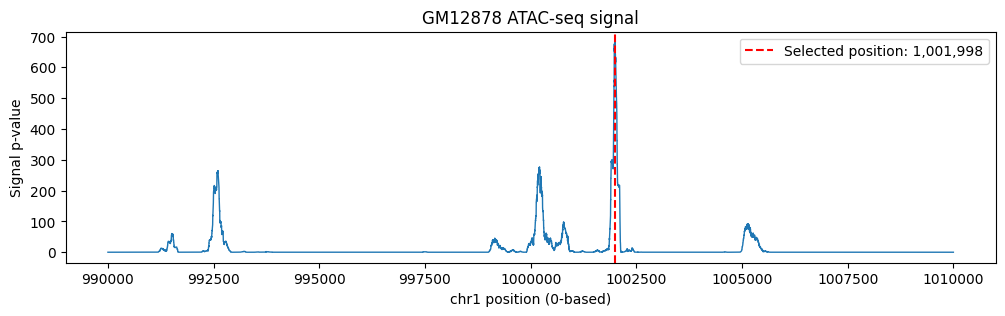

In [7]:
import matplotlib.pyplot as plt
import numpy as np

chrom = "chr1"
plot_start, plot_end = 990_000, 1_010_000
accession = "ENCFF667MDI"
accessions = ["ENCFF262URW", "ENCFF357GNC", "ENCFF667MDI", "ENCFF770EAV"]

bw = pybigtools.open(f"{data_dir}/{accession}.bigWig")
try:
    chrom_length = bw.chroms(chrom)
    print(f"length of the chromosome {chrom}: {chrom_length}")
    plot_signal = np.asarray(bw.values(chrom, plot_start, plot_end), dtype=float)
    print(f"len(plot_signal): {len(plot_signal)}")
finally:
    bw.close()

print([f"{value:.8f}" for value in plot_signal[:10]])

# get the max peak in this region
peak_position = plot_start + int(np.argmax(np.where(np.isfinite(plot_signal), plot_signal, -np.inf)))
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(np.arange(plot_start, plot_end), plot_signal, linewidth=1)
ax.axvline(peak_position, color="red", linestyle="--", label=f"Selected position: {peak_position:,}")
ax.set(title="GM12878 ATAC-seq signal", xlabel=f"{chrom} position (0-based)", ylabel="Signal p-value")
ax.ticklabel_format(axis="x", style="plain", useOffset=False)
ax.legend()
plt.show()

### How the features and labels are compared

To compare features and labels, we cut out a fixed window of the genome and pull both from the same coordinates. For example, we center a 2,048bp window on a chosen position, extract that stretch of DNA from the hg38 reference, and read the ATAC-seq signal for the same positions from the bigWig. The DNA is one-hot encoded into a 2,048 x 4 matrix. The signal has one value per base pair, so we group it into non-overlapping 4bp bins and keep the maximum of each, giving 512 target values for training. The central 256 correspond to the central 1,024 bp used for evaluation.

peak_position: 1001998
window_start: 1000974, window_end: 1003022
len(sequence_parts): 42
fasta_length: 248956422, chrom_length: 248956422
Number of base pairs in sequence: 2048
one_hot shape: (2048, 4)
first few rows of one_hot:
[[0 0 1 0]
 [1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [1 0 0 0]]
Aligned window: chr1:1,000,974-1,003,022 (0-based, end-exclusive)
Chromosome lengths match: 248,956,422 bases
DNA input shape: (2048, 4); 4-bp target shape: (512,)
Ambiguous DNA bases: 0
Missing signal values: 0; bins containing missing values: 0


,start (0-based),DNA,max signal
0,1000974,CAGC,4.78149
1,1000978,AGCA,4.78588
2,1000982,AAGT,5.05120
3,1000986,GGGG,4.77447
4,1000990,CTCA,4.77447
5,1000994,CAGA,4.39493
6,1000998,AAAA,4.14519
7,1001002,TGAG,3.55169
8,1001006,GGGC,3.55169
9,1001010,CACT,3.54947


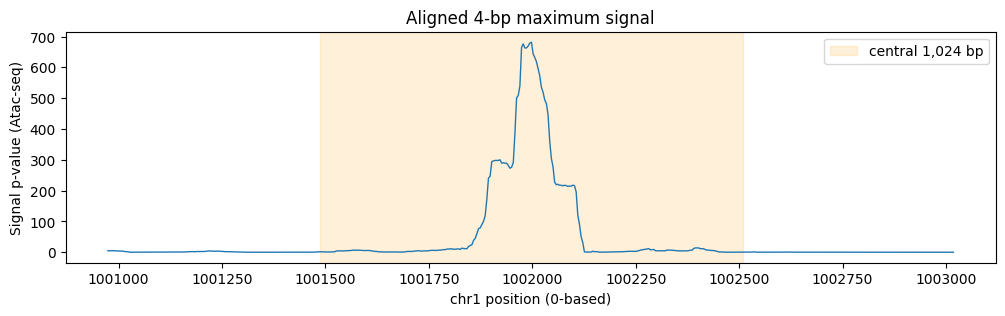

In [8]:
import pandas as pd
import pybigtools

reference_genome = "hg38"
chrom = "chr1"
accession = "ENCFF667MDI"
window_size = 2048
print(f"peak_position: {peak_position}")
window_start = peak_position - window_size // 2
window_end = window_start + window_size
print(f"window_start: {window_start}, window_end: {window_end}")

# Scan the compressed FASTA to extract the window and verify chromosome length.
sequence_parts = []
fasta_length = 0
found_chrom = False


with gzip.open(f"{data_dir}/{reference_genome}.fa.gz", "rt") as genome:
    for line in genome:
        if line.startswith(">"):
            # Stop after the we finish processing the chromosome listed above
            if found_chrom:
                break
            found_chrom = line[1:].split()[0] == chrom
            continue
        
        if found_chrom:
            bases = line.strip()
            line_end = fasta_length + len(bases)
            if fasta_length < window_end and line_end > window_start:
                sequence_parts.append(bases[max(0, window_start - fasta_length):min(len(bases), window_end - fasta_length)])
            fasta_length = line_end

print(f"len(sequence_parts): {len(sequence_parts)}")
print(f'fasta_length: {fasta_length}, chrom_length: {chrom_length}')
if fasta_length != chrom_length:
    raise ValueError(f"Chromosome length mismatch: FASTA={fasta_length}, bigWig={chrom_length}.")
sequence = "".join(sequence_parts).upper()
if len(sequence) != window_size:
    raise ValueError(f"Expected {window_size} bases, got {len(sequence)}.")

bw = pybigtools.open(f"{data_dir}/{accession}.bigWig")
try:
    signal = np.asarray(bw.values(chrom, window_start, window_end, fillna=None), dtype=float)
finally:
    bw.close()

print(f"Number of base pairs in sequence: {len(sequence)}")

def one_hot_encode_base_pairs(sequence: list[str]) -> list[list[int]]:
    """sequence like ["A", "C", "G", "T"]
    Return example: [[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]]
    """
    bases = np.array(list(sequence))
    possible_bases = np.array(["A", "G", "C", "T"])

    # return 1-D array into column to compare with possible_bases array
    one_hot = (bases[:, None] == possible_bases).astype(np.uint8)
    return one_hot

one_hot = one_hot_encode_base_pairs(sequence)

print(f"one_hot shape: {one_hot.shape}")
print(f"first few rows of one_hot:\n{one_hot[:5]}")
targets = signal.reshape(-1, 4).max(axis=1)
preview = pd.DataFrame({
    "start (0-based)": window_start + np.arange(512) * 4,
    "DNA": [sequence[i:i + 4] for i in range(0, window_size, 4)],
    "max signal": targets,
})

print(f"Aligned window: {chrom}:{window_start:,}-{window_end:,} (0-based, end-exclusive)")
print(f"Chromosome lengths match: {chrom_length:,} bases")
print(f"DNA input shape: {one_hot.shape}; 4-bp target shape: {targets.shape}")
print(f"Ambiguous DNA bases: {np.count_nonzero(one_hot.sum(axis=1) == 0)}") # Find any 'N' bases (missing)
print(f"Missing signal values: {np.isnan(signal).sum()}; bins containing missing values: {np.isnan(targets).sum()}")
display(preview.head(16))

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(preview["start (0-based)"], targets, linewidth=1)
ax.axvspan(window_start + 512, window_start + 1536, color="orange", alpha=0.15, label="central 1,024 bp")
ax.set(title="Aligned 4-bp maximum signal", xlabel=f"{chrom} position (0-based)", ylabel="Signal p-value (Atac-seq)")
ax.ticklabel_format(axis="x", style="plain", useOffset=False)
ax.legend()
plt.show()

## Pre-Processing

Load the data

In [21]:
from torch.utils.data import DataLoader
from data_loader import get_data_v2

if __name__ == "__main__":
    train_ds = get_data_v2("GM12878", fold=0, split="train")
    val_ds   = get_data_v2("GM12878", fold=0, split="val")
    test_ds  = get_data_v2("GM12878", fold=0, split="test")

    train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0)

    x, y = next(iter(train_dl))
    print(x.shape, y.shape)   # torch.Size([64, 4, 2048]) torch.Size([64, 512])

GM12878 fold 0 train: chr3: kept 92,229 of 96,824 windows
GM12878 fold 0 train: chr8: kept 66,335 of 70,868 windows
GM12878 fold 0 train: chr11: kept 61,081 of 65,960 windows
GM12878 fold 0 train: chr20: kept 28,823 of 31,466 windows
GM12878 fold 0 train: chr2: kept 110,376 of 118,258 windows
GM12878 fold 0 train: chr7: kept 70,926 of 77,805 windows
GM12878 fold 0 train: chr9: kept 51,621 of 67,575 windows
GM12878 fold 0 train: chr16: kept 35,068 of 44,110 windows
GM12878 fold 0 train: chr1: kept 103,535 of 121,560 windows
GM12878 fold 0 train: chr10: kept 60,733 of 65,330 windows
GM12878 fold 0 train: chr12: kept 61,384 of 65,075 windows
GM12878 fold 0 train: chr14: kept 41,463 of 52,267 windows
GM12878 fold 0 train: 783,574 windows total
GM12878 fold 0 val: chr6: kept 79,364 of 83,401 windows
GM12878 fold 0 val: chr15: kept 36,564 of 49,800 windows
GM12878 fold 0 val: chr17: kept 36,118 of 40,653 windows
GM12878 fold 0 val: chr18: kept 35,287 of 39,244 windows
GM12878 fold 0 val: chr

## Model

In [7]:
from Models.convnext_cnn import ConvNeXtCNN
from torchinfo import summary

model = ConvNeXtCNN()
print(model)
print('trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
summary(model, input_size=(64, 4, 2048))

ConvNeXtCNN(
  (stem): Sequential(
    (0): ConvNeXtV2Block(
      (dwconv): Conv1d(4, 128, kernel_size=(15,), stride=(1,), padding=same)
      (norm): LayerNorm((128,), eps=1e-06, elementwise_affine=True, bias=True)
      (pwconv1): Linear(in_features=128, out_features=512, bias=True)
      (act): GELU(approximate='none')
      (grn): GRN1d()
      (pwconv2): Linear(in_features=512, out_features=128, bias=True)
    )
    (1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (core): Sequential(
    (0): ConvNeXtV2Block(
      (dwconv): Conv1d(128, 256, kernel_size=(15,), stride=(1,), padding=same, groups=128)
      (norm): LayerNorm((256,), eps=1e-06, elementwise_affine=True, bias=True)
      (pwconv1): Linear(in_features=256, out_features=1024, bias=True)
      (act): GELU(approximate='none')
      (grn): GRN1d()
      (pwconv2): Linear(in_features=1024, out_features=256, bias=True)
    )
    (1): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1

Layer (type:depth-idx)                   Output Shape              Param #
ConvNeXtCNN                              [64, 512]                 --
├─Sequential: 1-1                        [64, 128, 1024]           --
│    └─ConvNeXtV2Block: 2-1              [64, 128, 2048]           --
│    │    └─Conv1d: 3-1                  [64, 128, 2048]           7,808
│    │    └─LayerNorm: 3-2               [64, 2048, 128]           256
│    │    └─Linear: 3-3                  [64, 2048, 512]           66,048
│    │    └─GELU: 3-4                    [64, 2048, 512]           --
│    │    └─GRN1d: 3-5                   [64, 2048, 512]           1,024
│    │    └─Linear: 3-6                  [64, 2048, 128]           65,664
│    └─MaxPool1d: 2-2                    [64, 128, 1024]           --
├─Sequential: 1-2                        [64, 512, 32]             --
│    └─ConvNeXtV2Block: 2-3              [64, 256, 1024]           --
│    │    └─Conv1d: 3-7                  [64, 256, 1024]           4,0

## Training

In [ ]:
from train import run_fold
# one fold
result = run_fold("GM12878", fold=0, epochs=10)


GM12878 fold 0 train: chr3: kept 92,229 of 96,824 windows
GM12878 fold 0 train: chr8: kept 66,335 of 70,868 windows
GM12878 fold 0 train: chr11: kept 61,081 of 65,960 windows
GM12878 fold 0 train: chr20: kept 28,823 of 31,466 windows
GM12878 fold 0 train: chr2: kept 110,376 of 118,258 windows
GM12878 fold 0 train: chr7: kept 70,926 of 77,805 windows
GM12878 fold 0 train: chr9: kept 51,621 of 67,575 windows
GM12878 fold 0 train: chr16: kept 35,068 of 44,110 windows
GM12878 fold 0 train: chr1: kept 103,535 of 121,560 windows
GM12878 fold 0 train: chr10: kept 60,733 of 65,330 windows
GM12878 fold 0 train: chr12: kept 61,384 of 65,075 windows
GM12878 fold 0 train: chr14: kept 41,463 of 52,267 windows
GM12878 fold 0 train: 783,574 windows total
GM12878 fold 0 val: chr6: kept 79,364 of 83,401 windows
GM12878 fold 0 val: chr15: kept 36,564 of 49,800 windows
GM12878 fold 0 val: chr17: kept 36,118 of 40,653 windows
GM12878 fold 0 val: chr18: kept 35,287 of 39,244 windows
GM12878 fold 0 val: chr

## Testing

In [ ]:
from evaluate_model import test_model

loss, pearson = test_model("GM12878", fold=0, max_batches=1)
# loss, pearson = test_model("GM12878", fold=0) # takes > 10 minutes / long time

Testing with device: cpu
Test chromosomes: ['chr4', 'chr5', 'chr13', 'chr19', 'chr22']
GM12878 fold 0 test: chr4: kept 88,192 of 92,878 windows
GM12878 fold 0 test: chr5: kept 82,177 of 88,641 windows
GM12878 fold 0 test: chr13: kept 45,380 of 55,841 windows
GM12878 fold 0 test: chr19: kept 25,479 of 28,621 windows
GM12878 fold 0 test: chr22: kept 16,004 of 24,813 windows
GM12878 fold 0 test: 257,232 windows total
Test loss: 0.2599
Test Pearson r: 0.2353


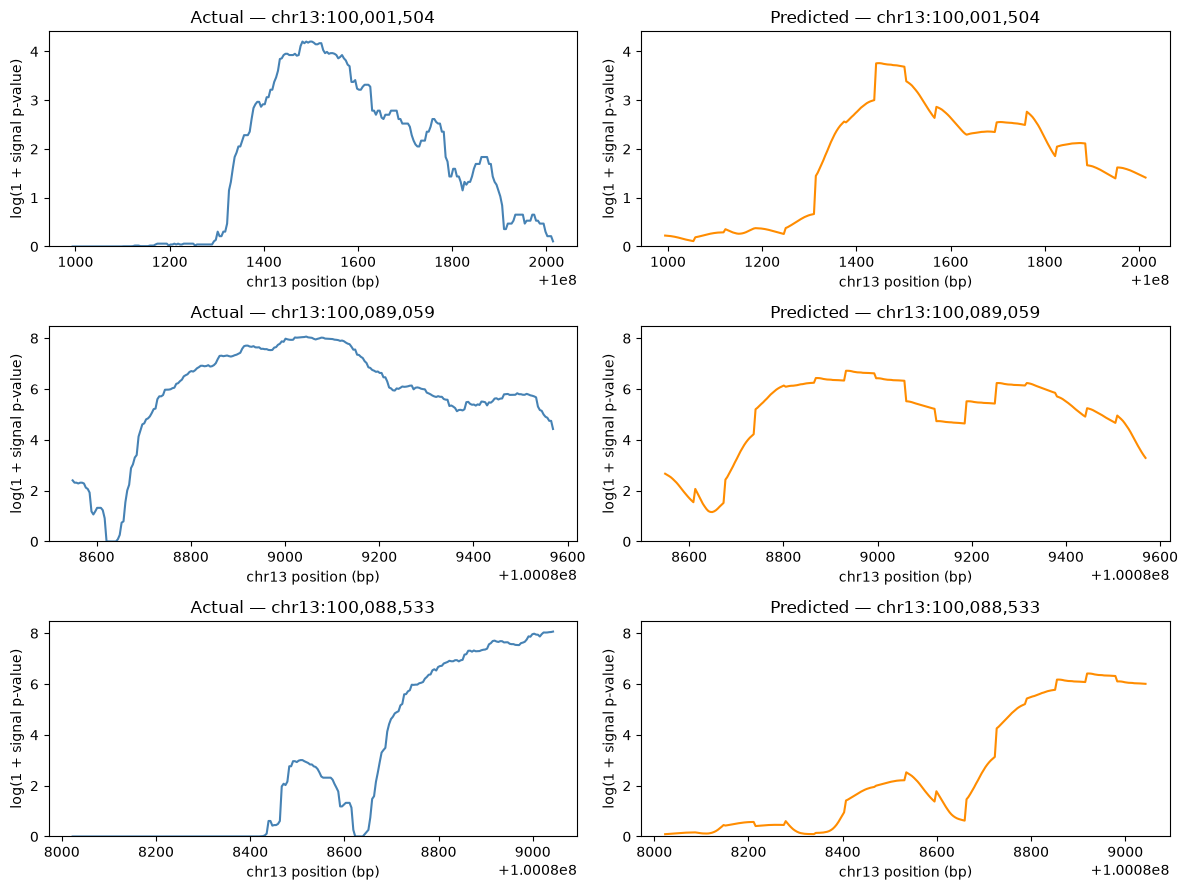

In [ ]:
from evaluate_model import plot_peaks

# Download the peak BED files from the README, then update the path below to wherever you saved it

fig = plot_peaks(
    "GM12878",
    fold=0,
    peak_file="data/peaks/ENCFF748UZH.bed.gz",
    n_peaks=3,
)

fig.savefig("outputs/peak_predictions.png", dpi=300, bbox_inches="tight")
plt.show()